<a href="https://colab.research.google.com/github/gowriv05/Final_Project_Python/blob/main/In_Vehicle_Coupon_Acceptance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **In-Vehicle Coupon Acceptance Analysis**

# Problem Statement

1. Customers are presented with different coupons while travelling under different driving conditions. However, customers may not accept all the coupons they receive.

2. The objective of this project is to analyze customer behavior and identify the factors associated with coupon acceptance.

3. The analysis will consider customer demographics, travel conditions, coupon types, coupon expiration, visiting habits, distance to the coupon location, and direction of travel.

4. The final analysis will help identify patterns in customer coupon acceptance behavior and provide meaningful business insights and recommendations.

# Outcome

The project aims to identify the major patterns and factors associated with customer coupon acceptance.

The analysis will provide insights into:

- Which coupon types have higher acceptance
- Which customer groups are more likely to accept coupons
- Whether travel conditions are associated with coupon acceptance
- Whether coupon expiration affects acceptance
- Whether visiting habits are associated with coupon acceptance
- Whether distance to the coupon location is associated with acceptance
- Whether travel direction is associated with coupon acceptance

The findings will be summarized into actionable business insights and recommendations.

# Domain
Marketing Analytics

**Source:** UCI Machine Learning Repository(https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation)

**Year / Timeline:** The dataset is associated with a research paper published in 2017. The exact data collection period is not specified in the official UCI documentation.

# Dataset Column / Features Description

### 1. destination
It describes the customer's current destination while travelling. The possible values include No Urgent Place, Home, and Work.

### 2. passanger
It describes who is travelling with the customer in the vehicle. Possible values include Alone, Friend(s), Kid(s), and Partner.

### 3. weather
It describes the weather condition during the driving scenario. Possible values include Sunny, Rainy, and Snowy.

### 4. temperature
It represents the temperature during the driving scenario. The dataset contains values such as 30, 55, and 80.

### 5. time
It represents the time of the driving scenario. Examples include 7AM, 10AM, 2PM, 6PM, and 10PM.

### 6. coupon
It represents the type of coupon recommended to the customer. Examples include Bar, Coffee House, Restaurant(<20), Restaurant($20-$50), and Carry out & Take away.

### 7. expiration
It represents how long the coupon remains valid. The values are 1d (one day) and 2h (two hours).

### 8. gender
It represents the gender of the customer. The values are Female and Male.

### 9. age
It represents the age group of the customer. The dataset contains values such as below21, 21, 26, 31, 36, 41, 46, and 50plus.

### 10. maritalStatus
It represents the marital status of the customer. Examples include Single, Married partner, Unmarried partner, Divorced, and Widowed.

### 11. has_children
It indicates whether the customer has children. The value 1 represents Yes and 0 represents No.

### 12. education
It represents the customer's education level. Examples include High School Graduate, Some college - no degree, Associates degree, Bachelors degree, and Graduate degree.

### 13. occupation
It represents the customer's occupation or employment category.

### 14. income
It represents the customer's income range.

### 15. car
It represents information about the customer's car. Some values may be missing in this column.

### 16. Bar
It represents how frequently the customer visits a bar per month. Possible categories include never, less1, 1~3, 4~8, and gt8.

### 17. CoffeeHouse
It represents how frequently the customer visits a coffee house per month. Possible categories include never, less1, 1~3, 4~8, and gt8.

### 18. CarryAway
It represents how frequently the customer gets take-away food per month. Possible categories include never, less1, 1~3, 4~8, and gt8.

### 19. RestaurantLessThan20
It represents how frequently the customer visits restaurants where the average expense per person is less than $20 per month.

### 20. Restaurant20To50
It represents how frequently the customer visits restaurants where the average expense per person is between $20 and $50 per month.

### 21. toCoupon_GEQ5min
It indicates whether the driving distance to the coupon location is at least 5 minutes.

### 22. toCoupon_GEQ15min
It indicates whether the driving distance to the coupon location is greater than or equal to 15 minutes.

### 23. toCoupon_GEQ25min
It indicates whether the driving distance to the coupon location is greater than or equal to 25 minutes.

### 24. direction_same
It indicates whether the coupon location is in the same direction as the customer's current destination.

### 25. direction_opp
It indicates whether the coupon location is in the opposite direction from the customer's current destination.

### 26. Y
It is the target variable that indicates whether the customer accepted the coupon. The value 1 represents coupon accepted and 0 represents coupon not accepted.

### Explanation

The required Python libraries are imported for data loading, data manipulation, numerical analysis, and visualization.

In [ ]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### Dataset Loading

The dataset was loaded into a Pandas DataFrame for further analysis and preprocessing.

In [ ]:
url="https://github.com/gowriv05/Final_Project_Python/raw/refs/heads/main/in-vehicle-coupon-recommendation.csv"
df=pd.read_csv(url)

### Dataset Shape

The dataset shape was checked to identify the total number of rows and columns available for analysis.

In [ ]:
df.shape

(12684, 26)

### First Five Records

The first five records were examined to understand the structure of the dataset and the type of information available in each column.

In [ ]:
df.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


### Last Five Records

The last five records were examined to verify the dataset structure and ensure that the data was loaded correctly.

In [ ]:
df.tail()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
12679,Home,Partner,Rainy,55,6PM,Carry out & Take away,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,0,0,1,0,1
12680,Work,Alone,Rainy,55,7AM,Carry out & Take away,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,0,0,0,1,1
12681,Work,Alone,Snowy,30,7AM,Coffee House,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,0,0,1,0,0
12682,Work,Alone,Snowy,30,7AM,Bar,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,1,1,0,1,0
12683,Work,Alone,Sunny,80,7AM,Restaurant(20-50),2h,Male,26,Single,...,never,1~3,4~8,1~3,1,0,0,1,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

### Data Type Inspection

The data types of all columns were examined using the 'info()' function.

The dataset contains both categorical and numerical variables. Categorical variables such as destination, weather, coupon, gender, age, education, occupation, and income are represented as object data types.

Numerical variables such as temperature, has_children, distance-related indicators, direction indicators, and the target variable Y are represented as integer data types.

The existing data types were reviewed based on the meaning of each variable. No unnecessary data type conversion was performed at this stage.

In [ ]:
df.describe()

,temperature,has_children,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
count,12684.000000,12684.000000,12684.0,12684.000000,12684.000000,12684.000000,12684.000000,12684.000000
mean,63.301798,0.414144,1.0,0.561495,0.119126,0.214759,0.785241,0.568433
std,19.154486,0.492593,0.0,0.496224,0.323950,0.410671,0.410671,0.495314
min,30.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,55.000000,0.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
50%,80.000000,0.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
75%,80.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
max,80.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
df.columns

Index(['destination', 'passanger', 'weather', 'temperature', 'time', 'coupon',
       'expiration', 'gender', 'age', 'maritalStatus', 'has_children',
       'education', 'occupation', 'income', 'car', 'Bar', 'CoffeeHouse',
       'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50',
       'toCoupon_GEQ5min', 'toCoupon_GEQ15min', 'toCoupon_GEQ25min',
       'direction_same', 'direction_opp', 'Y'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
destination,0
passanger,0
weather,0
temperature,0
time,0
coupon,0
expiration,0
gender,0
age,0
maritalStatus,0


In [ ]:
missing_percentage=(df.isnull().sum()/len(df))*100
missing_percentage

,0
destination,0.000000
passanger,0.000000
weather,0.000000
temperature,0.000000
time,0.000000
coupon,0.000000
expiration,0.000000
gender,0.000000
age,0.000000
maritalStatus,0.000000


In [ ]:
df['car'].isnull().mean()*100

np.float64(99.14853358561967)

# Duplicate Value Check

Duplicate rows were checked to identify repeated records in the dataset.*italicized text*

In [ ]:
df.duplicated().sum()

np.int64(74)

In [ ]:
# view duplicates
df[df.duplicated]

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
4192,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,never,1~3,less1,less1,1,1,1,0,1,1
4236,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,gt8,gt8,4~8,less1,1,1,1,0,1,1
4280,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,26,Single,...,never,4~8,1~3,less1,1,1,1,0,1,1
4324,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,46,Single,...,never,4~8,1~3,1~3,1,1,1,0,1,1
4409,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,21,Single,...,never,less1,1~3,never,1,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8511,Home,Alone,Sunny,80,6PM,Bar,2h,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,0,0,1,0,1
8512,Home,Partner,Sunny,30,10PM,Carry out & Take away,2h,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,1,0,0,1,1
8513,Work,Alone,Rainy,55,7AM,Restaurant(<20),2h,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,1,1,0,1,0
8515,Work,Alone,Snowy,30,7AM,Restaurant(20-50),1d,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,1,1,0,1,0


In [ ]:
# remove duplicates
df=df.drop_duplicates()
# shape after removing duplicates
df.shape

(12610, 26)

In [ ]:
df.duplicated().sum()

np.int64(0)

### Final Duplicate Check

After removing the identified duplicate records, the dataset was checked again to confirm that no exact duplicate rows remain.

Removing the Car Column

The 'car' column contains approximately 99.1% missing values.
Since most of the information is missing, the column provides very limited useful information for analysis.
Therefore, the 'car' column was removed from the dataset.

In [ ]:
df.drop(columns=['car'], inplace=True, errors='ignore')

In [ ]:
'car' in df.columns

False

In [ ]:
# After removing car column
df.isnull().sum()

,0
destination,0
passanger,0
weather,0
temperature,0
time,0
coupon,0
expiration,0
gender,0
age,0
maritalStatus,0


In [ ]:
# Handling missing values
df=df.dropna()
print("Rows after removing missing values:")
df.shape

Rows after removing missing values:


(12007, 25)

In [ ]:
df.isnull().sum()

,0
destination,0
passanger,0
weather,0
temperature,0
time,0
coupon,0
expiration,0
gender,0
age,0
maritalStatus,0


### Final Missing Value Check

The dataset was checked again after the missing value treatment to ensure that no significant missing values remain in the cleaned dataset.

In [ ]:
categorical_columns=df.select_dtypes(include="object").columns
print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['destination', 'passanger', 'weather', 'time', 'coupon', 'expiration',
       'gender', 'age', 'maritalStatus', 'education', 'occupation', 'income',
       'Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20',
       'Restaurant20To50'],
      dtype='object')


In [ ]:
for col in categorical_columns:
  print("\n")
  print("Column:", col)
  print(df[col].value_counts())



Column: destination
destination
No Urgent Place    5953
Home               3078
Work               2976
Name: count, dtype: int64


Column: passanger
passanger
Alone        6914
Friend(s)    3142
Partner      1018
Kid(s)        933
Name: count, dtype: int64


Column: weather
weather
Sunny    9545
Snowy    1323
Rainy    1139
Name: count, dtype: int64


Column: time
time
6PM     3068
7AM     2976
10AM    2154
2PM     1913
10PM    1896
Name: count, dtype: int64


Column: coupon
coupon
Coffee House             3809
Restaurant(<20)          2646
Carry out & Take away    2233
Bar                      1906
Restaurant(20-50)        1413
Name: count, dtype: int64


Column: expiration
expiration
1d    6702
2h    5305
Name: count, dtype: int64


Column: gender
gender
Female    6158
Male      5849
Name: count, dtype: int64


Column: age
age
21         2526
26         2388
31         1906
50plus     1725
36         1251
41         1061
46          648
below21     502
Name: count, dtype: int64


C

### Categorical Value Validation

The categorical variables were reviewed to identify their unique categories and frequency distributions.

This step helps verify that the categorical values are meaningful and consistent before performing exploratory analysis.

In [ ]:
habit_columns=["Bar","CoffeeHouse","CarryAway","RestaurantLessThan20","Restaurant20To50"]
for col in habit_columns:
    print("\n",col)
    print(df[col].value_counts())


 Bar
Bar
never    4916
less1    3351
1~3      2365
4~8      1049
gt8       326
Name: count, dtype: int64

 CoffeeHouse
CoffeeHouse
less1    3276
1~3      3133
never    2836
4~8      1655
gt8      1107
Name: count, dtype: int64

 CarryAway
CarryAway
1~3      4475
4~8      4068
less1    1783
gt8      1551
never     130
Name: count, dtype: int64

 RestaurantLessThan20
RestaurantLessThan20
1~3      5143
4~8      3424
less1    1983
gt8      1282
never     175
Name: count, dtype: int64

 Restaurant20To50
Restaurant20To50
less1    5825
1~3      3178
never    2056
4~8       684
gt8       264
Name: count, dtype: int64


### Customer Visiting Habit Variables

The variables Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, and Restaurant20To50 represent the customer's general visiting frequency for different types of establishments.

The values are categorical frequency groups such as 'never', 'less1', '1-3', '4-8', and 'gt8'.

These variables represent general customer habits and do not necessarily indicate visits made using the offered coupon. Therefore, they are treated as categorical frequency variables rather than continuous numerical variables.

In [ ]:
binary_columns=["has_children","toCoupon_GEQ5min","toCoupon_GEQ15min","toCoupon_GEQ25min","direction_same","direction_opp","Y"]
for col in binary_columns:
    print("\n", col)
    print(df[col].value_counts())


 has_children
has_children
0    7098
1    4909
Name: count, dtype: int64

 toCoupon_GEQ5min
toCoupon_GEQ5min
1    12007
Name: count, dtype: int64

 toCoupon_GEQ15min
toCoupon_GEQ15min
1    6718
0    5289
Name: count, dtype: int64

 toCoupon_GEQ25min
toCoupon_GEQ25min
0    10611
1     1396
Name: count, dtype: int64

 direction_same
direction_same
0    9414
1    2593
Name: count, dtype: int64

 direction_opp
direction_opp
1    9414
0    2593
Name: count, dtype: int64

 Y
Y
1    6825
0    5182
Name: count, dtype: int64


### Binary Variable Validation

The binary variables were checked to confirm that they contain valid 0 and 1 values.

In this dataset, 0 and 1 represent meaningful categories or indicators rather than continuous numerical measurements. Therefore, these variables were retained without outlier removal or unnecessary transformation.

The target variable Y represents coupon acceptance, where 1 indicates acceptance and 0 indicates non-acceptance.

In [ ]:
numerical_columns=df.select_dtypes(include=np.number).columns
for col in numerical_columns:
    print("\nColumn:",col)
    print("Unique values:",df[col].unique())


Column: temperature
Unique values: [55 80 30]

Column: has_children
Unique values: [0 1]

Column: toCoupon_GEQ5min
Unique values: [1]

Column: toCoupon_GEQ15min
Unique values: [0 1]

Column: toCoupon_GEQ25min
Unique values: [0 1]

Column: direction_same
Unique values: [0 1]

Column: direction_opp
Unique values: [1 0]

Column: Y
Unique values: [1 0]


### Outlier Analysis

The numerical variables were reviewed based on their unique values and business meaning.

Most numerical variables in this dataset are discrete or binary indicators rather than continuous measurements. Therefore, traditional outlier detection techniques like IQR,Skewness are not appropriate for these variables.

No observations were removed as statistical outliers. Instead, the numerical values were checked for invalid or unexpected values based on the definition of each variable.

In [ ]:
df.rename(columns={"passanger":"passenger","maritalStatus":"marital_status","RestaurantLessThan20":"restaurant_less_than_20",
                   "Restaurant20To50":"restaurant_20_to_50"},inplace=True)

In [ ]:
df.columns

Index(['destination', 'passenger', 'weather', 'temperature', 'time', 'coupon',
       'expiration', 'gender', 'age', 'marital_status', 'has_children',
       'education', 'occupation', 'income', 'Bar', 'CoffeeHouse', 'CarryAway',
       'restaurant_less_than_20', 'restaurant_20_to_50', 'toCoupon_GEQ5min',
       'toCoupon_GEQ15min', 'toCoupon_GEQ25min', 'direction_same',
       'direction_opp', 'Y'],
      dtype='object')

### Column Name Standardization

Selected column names were standardized to improve readability and maintain a consistent naming convention.

The original meaning of the variables was preserved while correcting naming inconsistencies and improving usability during analysis.

In [ ]:
print("Final cleaned dataset shape:",df.shape)
print("\nMissing values:",df.isnull().sum().sum())
print("\nDuplicate rows:",df.duplicated().sum())

Final cleaned dataset shape: (12007, 25)

Missing values: 0

Duplicate rows: 0


### Final Pre-processing Validation

The cleaned dataset was validated after completing the preprocessing steps.

The final dataset was checked for remaining missing values, duplicate records, and its overall structure before proceeding to exploratory data analysis and visualization.

In [ ]:
acceptance_counts=df["Y"].value_counts()
print("Coupon Acceptance Count:")
print(acceptance_counts)

Coupon Acceptance Count:
Y
1    6825
0    5182
Name: count, dtype: int64


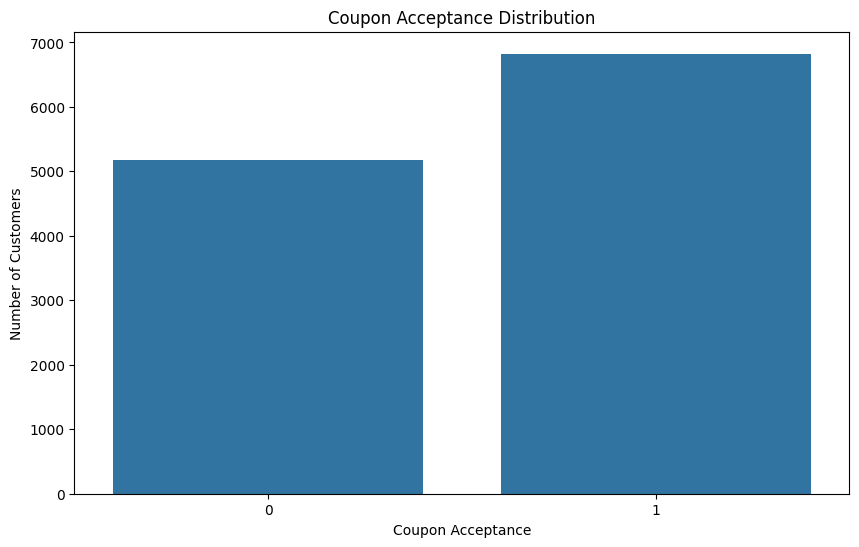

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(data=df,x="Y")
plt.title("Coupon Acceptance Distribution")
plt.xlabel("Coupon Acceptance")
plt.ylabel("Number of Customers")
plt.show()

### Interpretation

This visualization shows the overall distribution of coupon acceptance and non-acceptance.

### Business Insight

The overall coupon acceptance rate provides a baseline for comparing acceptance across different customer groups, coupon types, and travel conditions.Out of 12,007 coupon offers, 6,825 coupons were accepted and 5,182 were rejected.

Approximately more than 55% of coupon offers were accepted.



In [ ]:
coupon_acceptance=pd.crosstab(df["coupon"],df["Y"],normalize="index")*100
coupon_acceptance

Y,0,1
coupon,,
Bar,58.814271,41.185729
Carry out & Take away,26.421854,73.578146
Coffee House,50.433185,49.566815
Restaurant(20-50),55.343241,44.656759
Restaurant(<20),29.024943,70.975057


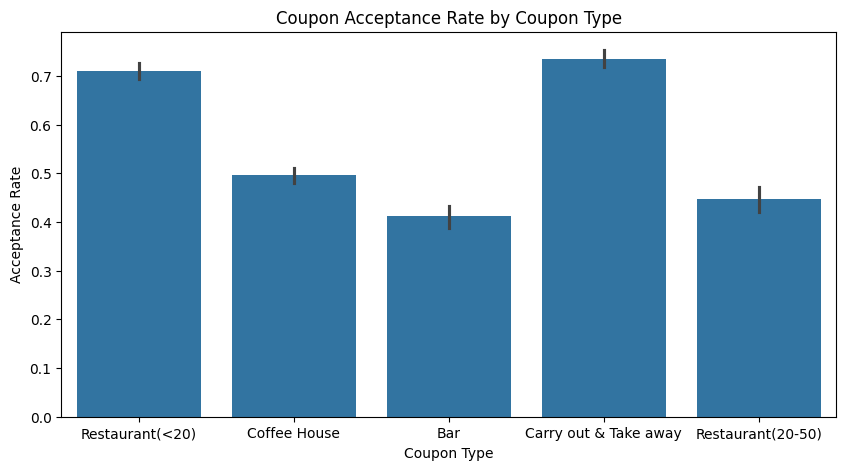

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="coupon",y="Y")
plt.title("Coupon Acceptance Rate by Coupon Type")
plt.xlabel("Coupon Type")
plt.ylabel("Acceptance Rate")
plt.show()

### Interpretation

Interpretation: Carry out & Take away coupons had the highest acceptance rate at 73.57%, followed by Restaurant(<20) coupons at 71%. Bar coupons had the lowest acceptance rate at 41.00%.

Business Insight: Carry out & Take away and Restaurant(<20) coupons received higher acceptance rates than the other coupon categories. These coupon types may be worth considering when planning future promotions.

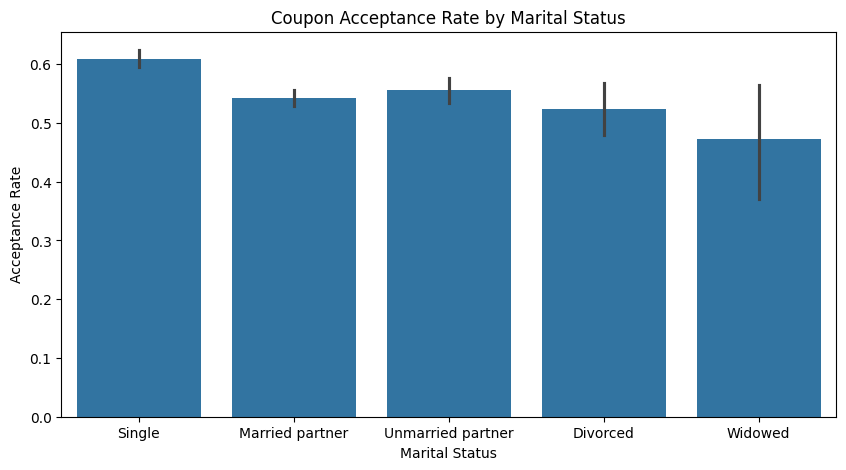

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="marital_status",y="Y")
plt.title("Coupon Acceptance Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Acceptance Rate")
plt.show()

### Business Insight
Single customers have the highest coupon acceptance rate, at more than 60%, while widowed customers have the lowest acceptance rate, at approximately 48%.

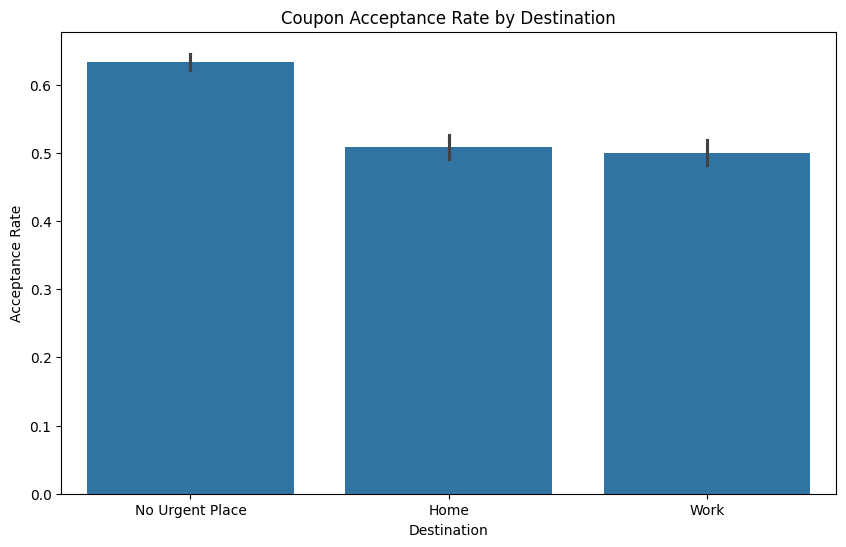

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x="destination",y="Y",estimator="mean")
plt.title("Coupon Acceptance Rate by Destination")
plt.xlabel("Destination")
plt.ylabel("Acceptance Rate")
plt.show()

Interpretation: Customers travelling to No Urgent Place had the highest acceptance rate at 63.40%. Customers travelling Home had a rate of 50.50%, while customers travelling to Work had the lowest rate at 50.25%.

Business Insight: Customers without an urgent destination showed higher coupon acceptance in this dataset. Flexible travel situations may provide opportunities for targeted coupon promotions.



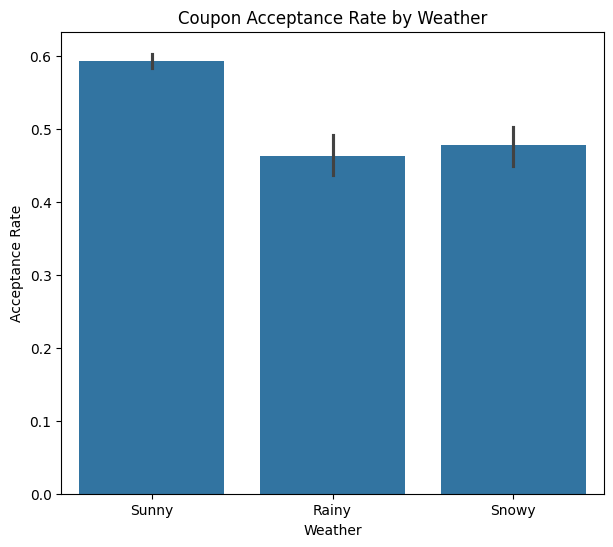

In [ ]:
plt.figure(figsize=(7,6))
sns.barplot(data=df,x="weather",y="Y",estimator="mean")
plt.title("Coupon Acceptance Rate by Weather")
plt.xlabel("Weather")
plt.ylabel("Acceptance Rate")
plt.show()

Interpretation: Sunny weather had the highest coupon acceptance rate at 59.50%. Snowy weather had an acceptance rate of 47%, while rainy weather had the lowest rate at 46.25%.

Business Insight: Coupon acceptance was higher in sunny weather than in rainy or snowy weather. Marketing teams could investigate whether weather-based promotions improve customer engagement.

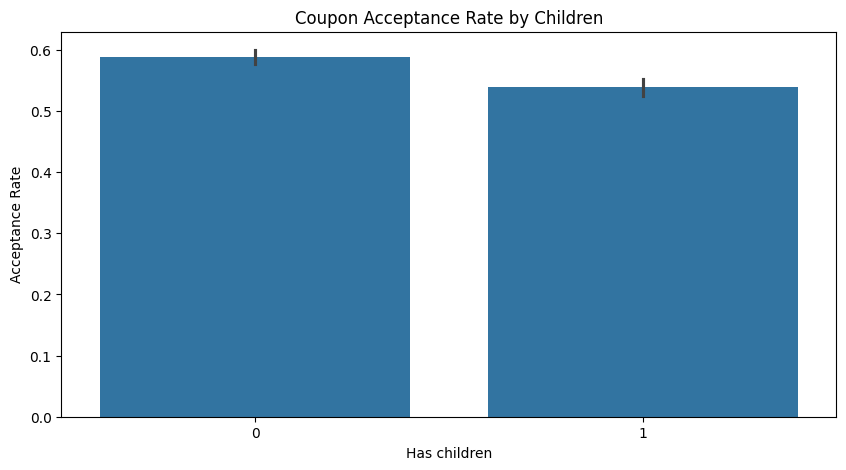

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="has_children",y="Y")
plt.title("Coupon Acceptance Rate by Children")
plt.xlabel("Has children")
plt.ylabel("Acceptance Rate")
plt.show()

### Business Insights:
Customers without children have a higher coupon acceptance rate of approximately 58%, compared to approximately 55% for customers with children.

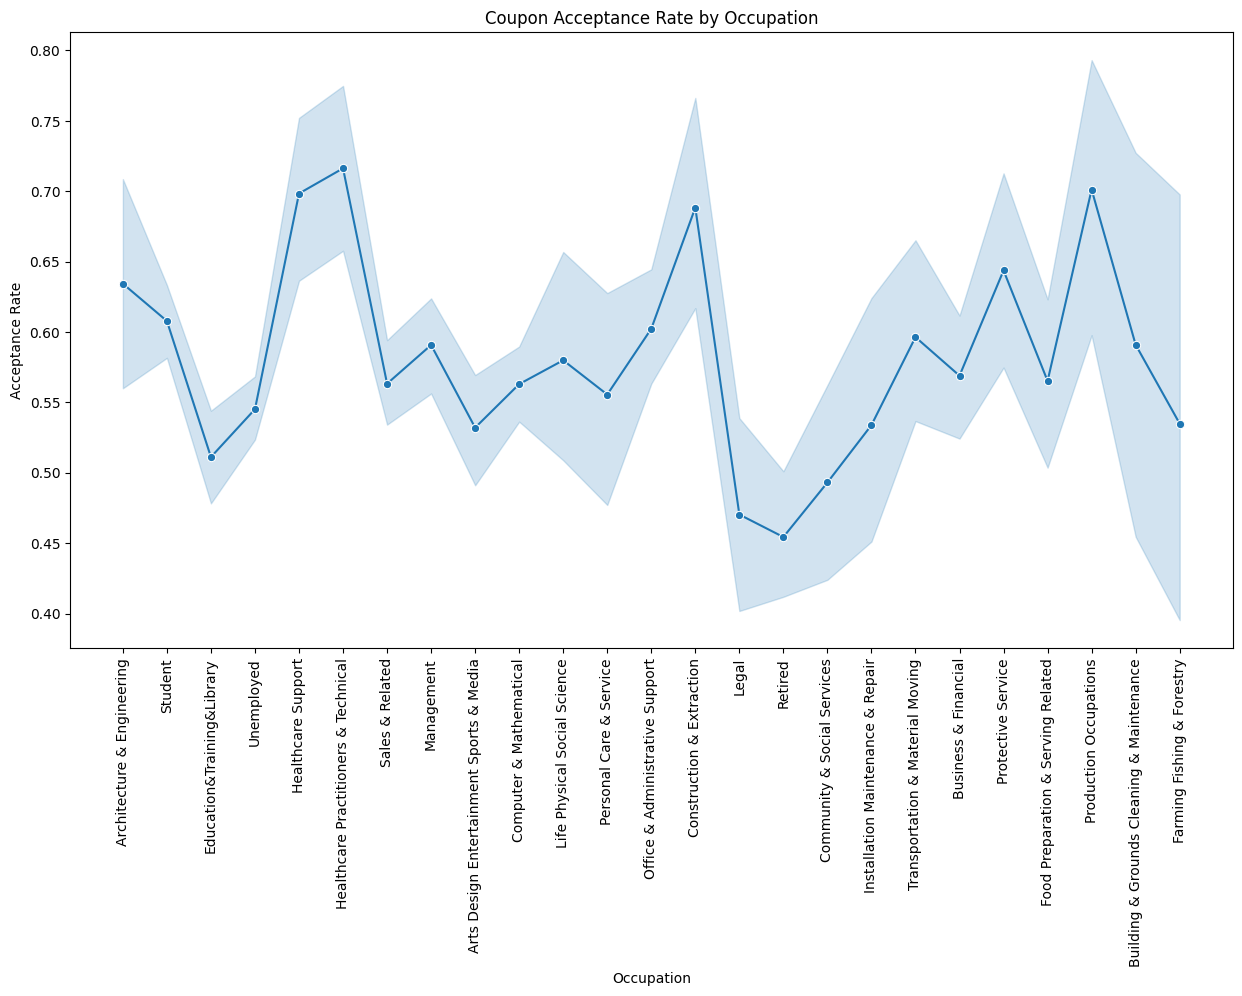

In [ ]:
plt.figure(figsize=(15,8))
sns.lineplot(data=df,x="occupation",y="Y",estimator="mean",marker="o")
plt.title("Coupon Acceptance Rate by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Acceptance Rate")
plt.xticks(rotation=90)
plt.show()

### Business Insights
Customers working in Healthcare Practitioners and Technical occupations have the highest coupon acceptance rate, at more than 70%.

Retired customers have a lower coupon acceptance rate, at approximately 46–47%.

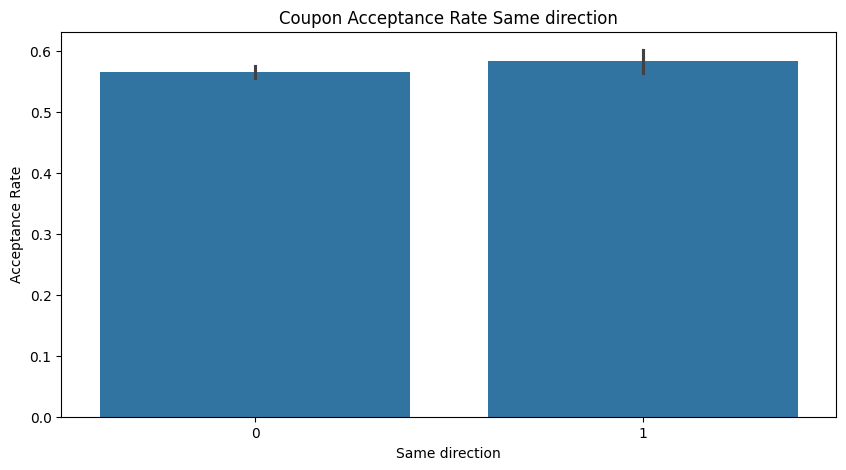

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="direction_same",y="Y")
plt.title("Coupon Acceptance Rate Same direction")
plt.xlabel("Same direction")
plt.ylabel("Acceptance Rate")
plt.show()

### Business Insights:
Customers travelling in the same direction as the destination have a higher coupon acceptance rate than customers travelling in the opposite direction.

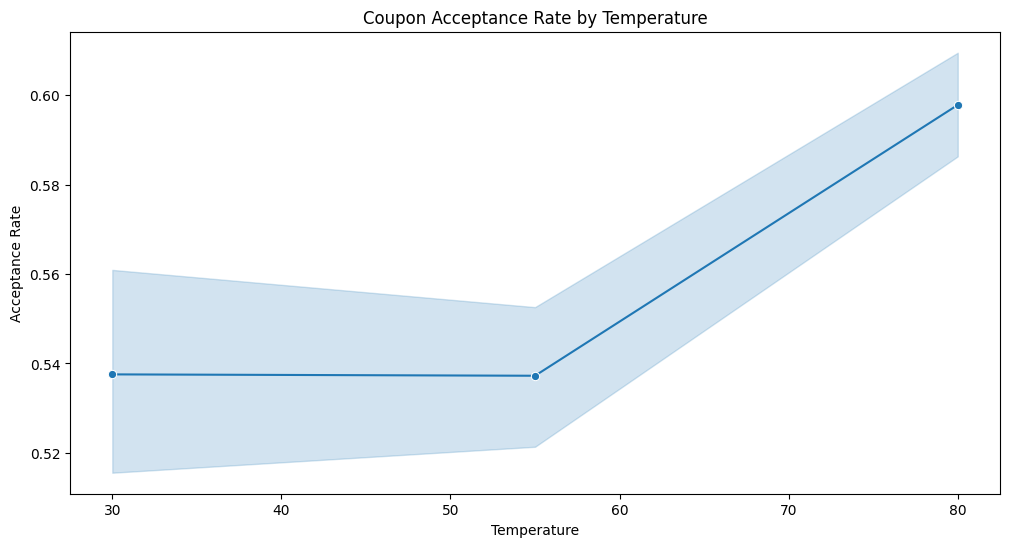

In [ ]:
plt.figure(figsize=(12,6))
sns.lineplot(data=df,x="temperature",y="Y",estimator="mean",marker="o")
plt.title("Coupon Acceptance Rate by Temperature")
plt.xlabel("Temperature")
plt.ylabel("Acceptance Rate")
plt.show()

Interpretation: The 80°F temperature category had the highest acceptance rate at 60%. The rate was 53.70% at 55°F and 53.10% at 30°F.

Business Insight: Coupon acceptance was highest in the warmest temperature category recorded in the dataset. Further analysis could examine whether this pattern differs across coupon types.

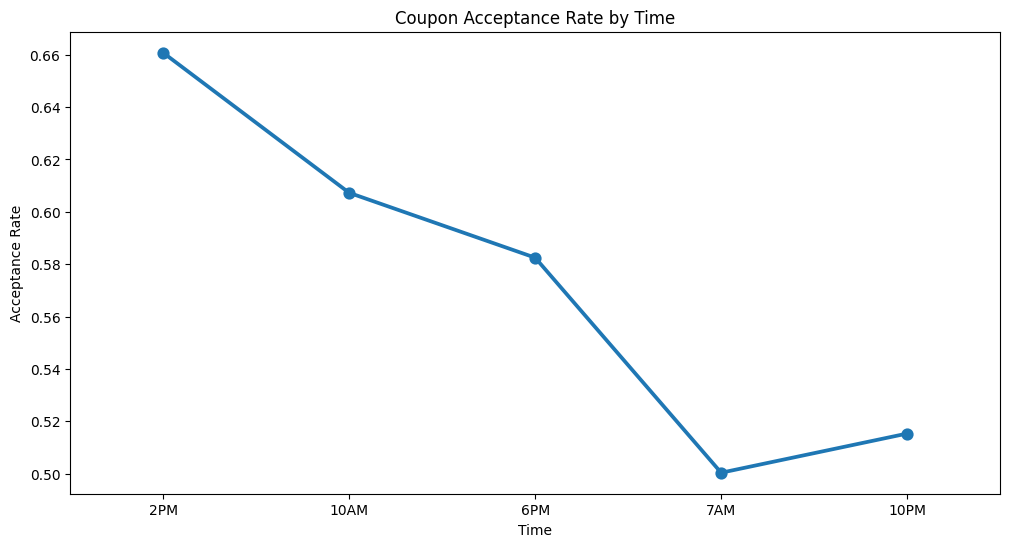

In [ ]:
plt.figure(figsize=(12,6))
sns.pointplot(data=df,x="time",y="Y",estimator="mean",errorbar=None)
plt.title("Coupon Acceptance Rate by Time")
plt.xlabel("Time")
plt.ylabel("Acceptance Rate")
plt.show()

Interpretation: 2 PM had the highest coupon acceptance rate at 66.10%. The acceptance rate was 60.85% at 10 AM and 50.20% at 7 AM, which was the lowest among the recorded time categories.

Business Insight: Coupon acceptance was highest at 2 PM in this dataset. Businesses could investigate afternoon promotions while considering differences between coupon types.

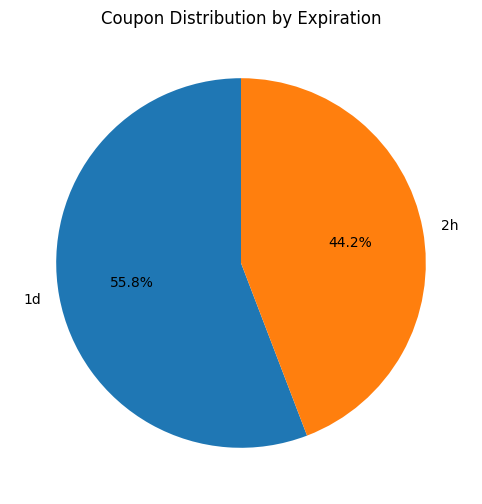

In [ ]:
expiration_counts=df["expiration"].value_counts()
plt.figure(figsize=(10,6))
plt.pie(expiration_counts,labels=expiration_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Coupon Distribution by Expiration")
plt.show()

### Interpretation:
The pie chart shows the distribution of coupons based on their expiration period. It compares the proportion of coupons that expire in one day with those that expire in two hours.

### Business Insight:
Coupons with a one-day validity period had a higher acceptance rate (55.8%) than coupons with a two-hour (42.2%) validity period. Longer validity may give customers more flexibility to use an offer.

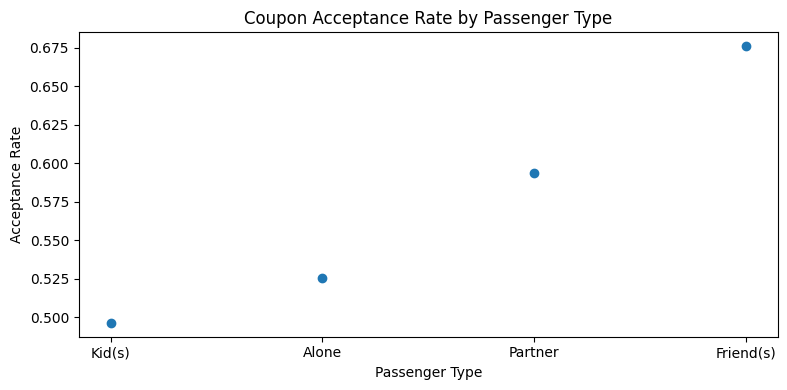

In [ ]:
acceptance=df.groupby("passenger")["Y"].mean().sort_values()
plt.figure(figsize=(8,4))
plt.scatter(x=acceptance.index,y=acceptance.values)
plt.title("Coupon Acceptance Rate by Passenger Type")
plt.xlabel("Passenger Type")
plt.ylabel("Acceptance Rate")
plt.tight_layout()
plt.show()

###Interpretation:
The chart compares coupon acceptance rates according to the passenger accompanying the driver.

###Business Insight:
Customers travelling with friends had the highest acceptance rate at 67.30%. Businesses could test group-oriented offers to see whether they improve coupon engagement.

In [ ]:
coffee_data=df[df["coupon"]=="Coffee House"]

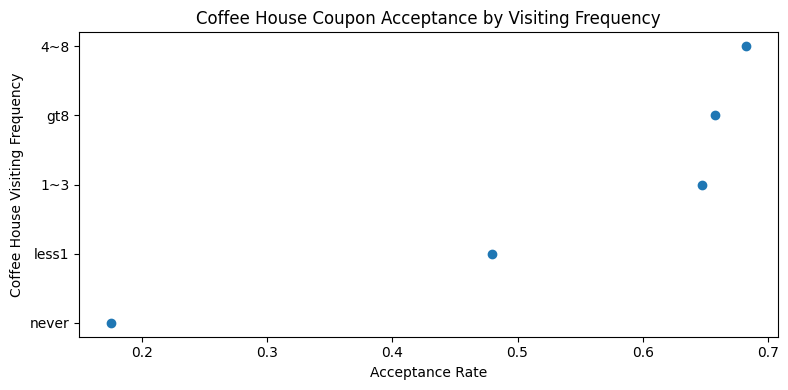

In [ ]:
coffee_acceptance=(coffee_data.groupby("CoffeeHouse")["Y"].mean().sort_values())
plt.figure(figsize=(8,4))
plt.scatter(coffee_acceptance.values,coffee_acceptance.index)
plt.title("Coffee House Coupon Acceptance by Visiting Frequency")
plt.xlabel("Acceptance Rate")
plt.ylabel("Coffee House Visiting Frequency")
plt.tight_layout()
plt.show()

### Interpretation:
This chart compares acceptance rates for Coffee House coupons across respondents' reported CoffeeHouse visiting frequencies.

### Business Insight:
Customers who visit coffee houses 4–8 times are more likely to accept coupons, with an acceptance rate of approximately 68%.

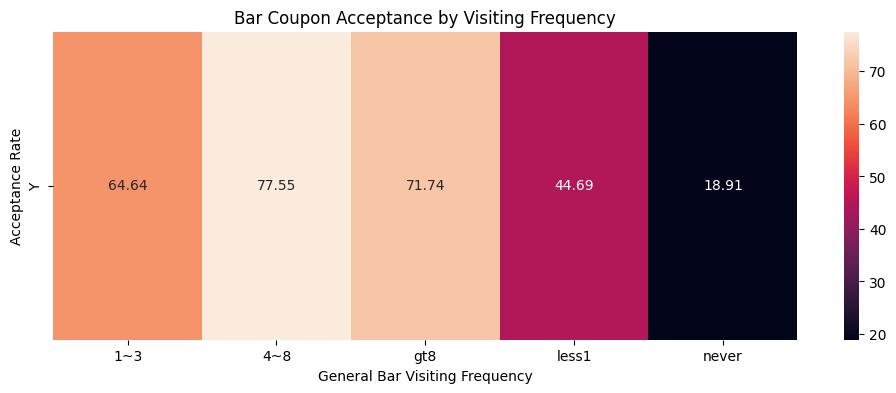

In [ ]:
bar_data=df[df["coupon"]=="Bar"]
acceptance=bar_data.groupby("Bar")["Y"].mean()*100
plt.figure(figsize=(12,4))
sns.heatmap(acceptance.to_frame().T,annot=True,fmt=".2f")
plt.title("Bar Coupon Acceptance by Visiting Frequency")
plt.xlabel("General Bar Visiting Frequency")
plt.ylabel("Acceptance Rate")
plt.show()

### Interpretation
The heatmap shows the coupon acceptance rate for each category of general bar-visiting frequency. Higher values indicate a higher proportion of customers accepting bar coupons, while lower values indicate a lower acceptance rate.
### Business Insights
Customers who visit bars 4–8 times are more likely to accept bar coupons.

Customers who never or rarely visit bars may need attractive discounts or special offers to encourage coupon acceptance.

In [ ]:
distance_columns=["toCoupon_GEQ5min","toCoupon_GEQ15min","toCoupon_GEQ25min"]
for col in distance_columns:
    print("\n")
    print(df.groupby(col)["Y"].mean()*100)



toCoupon_GEQ5min
1    56.841842
Name: Y, dtype: float64


toCoupon_GEQ15min
0    61.467196
1    53.200357
Name: Y, dtype: float64


toCoupon_GEQ25min
0    58.731505
1    42.478510
Name: Y, dtype: float64


In [ ]:
distance_summary=pd.DataFrame({
    "5min": df.groupby("toCoupon_GEQ5min")["Y"].mean()*100,
    "15min": df.groupby("toCoupon_GEQ15min")["Y"].mean()*100,
    "25min": df.groupby("toCoupon_GEQ25min")["Y"].mean()*100  })
distance_summary

,5min,15min,25min
0,NaN,61.467196,58.731505
1,56.841842,53.200357,42.478510


In [ ]:
direction_summary = pd.DataFrame({
    "Same Direction": df.groupby("direction_same")["Y"].mean()*100,
    "Opposite Direction": df.groupby("direction_opp")["Y"].mean()*100 })
direction_summary

,Same Direction,Opposite Direction
0,56.458466,58.233706
1,58.233706,56.458466


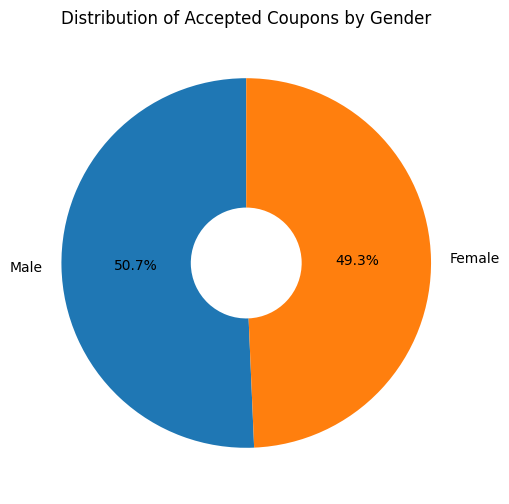

In [ ]:
gender_data=df[df["Y"]==1]["gender"].value_counts()
plt.figure(figsize=(10,6))
plt.pie(gender_data,labels=gender_data.index,autopct="%1.1f%%",startangle=90,wedgeprops={"width": 0.7})
plt.title("Distribution of Accepted Coupons by Gender")
plt.show()

### Interpretation
The donut chart shows the percentage distribution of accepted coupons by gender. It indicates how much each gender contributes to the total number of accepted coupons.
### Business Insights
Male customers account for a slightly higher share of total accepted coupons (50.7%), compared to female customers (49.3%).

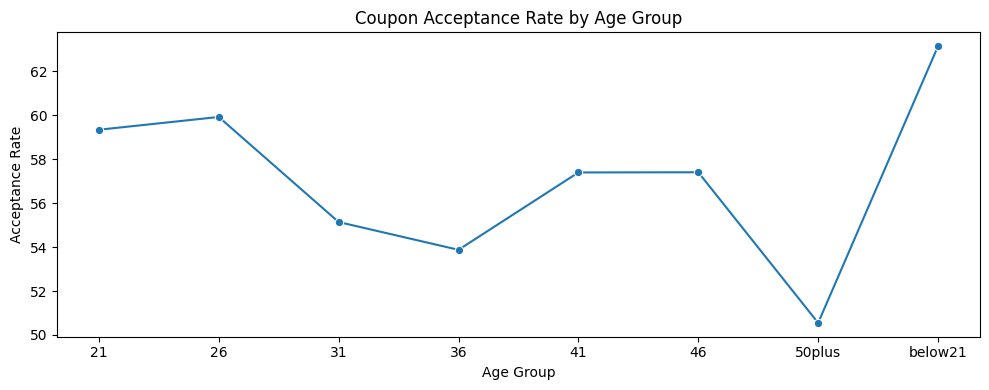

In [ ]:
age_acceptance=df.groupby("age")["Y"].mean()*100
plt.figure(figsize=(10,4))
sns.lineplot(x=age_acceptance.index,y=age_acceptance.values,marker="o")
plt.title("Coupon Acceptance Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Acceptance Rate")
plt.tight_layout()
plt.show()

### Interpretation
The line plot shows the coupon acceptance rate across different age groups. The acceptance rate varies by age group, indicating differences in customer responses to coupons.

### Business Insights
Customers below 21 years have the highest coupon acceptance rate, while customers aged 50 and above have the lowest acceptance rate

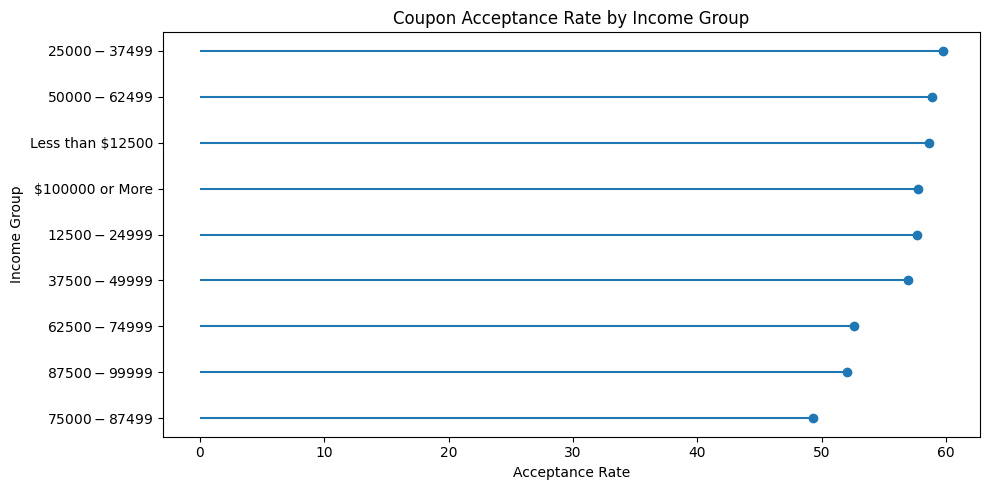

In [ ]:
income_acceptance=(df.groupby("income")["Y"].mean()*100).sort_values()
plt.figure(figsize=(10,5))
plt.hlines(y=income_acceptance.index,xmin=0,xmax=income_acceptance.values)
plt.scatter(income_acceptance.values,income_acceptance.index)
plt.title("Coupon Acceptance Rate by Income Group")
plt.xlabel("Acceptance Rate")
plt.ylabel("Income Group")
plt.tight_layout()
plt.show()

### Interpretation
The lollipop plot shows the coupon acceptance rate across different income groups. The acceptance rate varies among income groups, indicating differences in customers’ responses to coupons.
### Business Insights
Customers with an income of 25,000–37,499 have the highest coupon acceptance rate, while customers with an income of 75,000–87,499 have the lowest coupon acceptance rate.

In [ ]:
coupon_weather=pd.crosstab(df["coupon"],df["weather"],values=df["Y"],aggfunc="mean")
coupon_weather

weather,Rainy,Snowy,Sunny
coupon,,,
Bar,0.362963,0.324444,0.442790
Carry out & Take away,0.608696,0.713793,0.762774
Coffee House,0.516279,0.429577,0.500000
Restaurant(20-50),0.380952,0.315476,0.468697
Restaurant(<20),0.401274,0.497191,0.767932


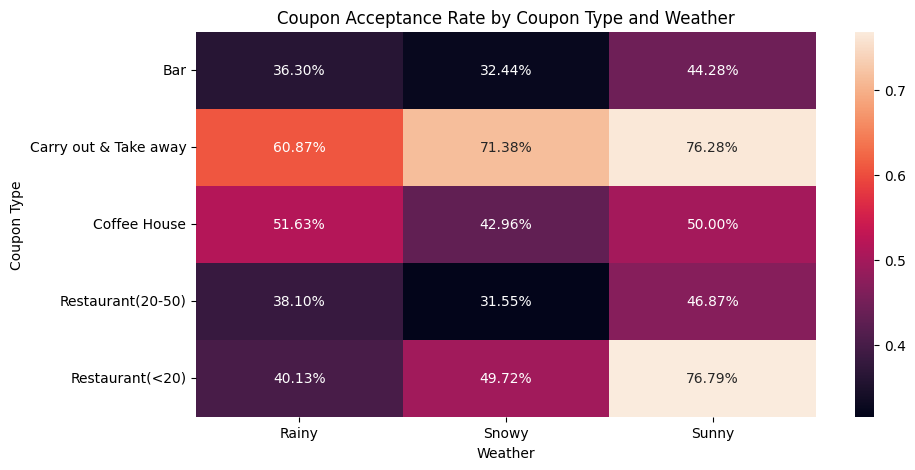

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(coupon_weather,annot=True,fmt=".2%")
plt.title("Coupon Acceptance Rate by Coupon Type and Weather")
plt.xlabel("Weather")
plt.ylabel("Coupon Type")
plt.show()

### Interpretation

The heatmap compares coupon acceptance rates across different coupon types and weather conditions.

This multivariate analysis provides a deeper understanding of how coupon type and travel conditions are associated with customer acceptance behavior.

### Business Insights
- Bar: Acceptance is highest in sunny weather (44.28%) and lowest in snowy weather (32.44%)
- Carry out & Take away: Acceptance is highest in sunny weather (76.28%) and lowest in rainy weather (60.87%)
- Coffee House: Acceptance is highest in rainy weather (51.63%) and lowest in snowy weather (42.96%)
- Restaurant (20–50): Acceptance is highest in sunny weather (46.87%) and lowest in snowy weather (31.55%)
- **Restaurant (< 20): Acceptance is highest in sunny weather (76,79%) and lowest in rainy weather (40.13%)

In [ ]:
coupon_time=pd.crosstab(df["coupon"],df["time"],values=df["Y"],aggfunc="mean")
coupon_time

time,10AM,10PM,2PM,6PM,7AM
coupon,,,,,
Bar,0.367788,0.464380,0.336283,0.462687,0.367965
Carry out & Take away,0.698770,0.766590,0.866029,0.819951,0.652616
Coffee House,0.634346,0.429078,0.544855,0.410405,0.440000
Restaurant(20-50),0.607477,0.339888,0.545977,0.502717,0.404412
Restaurant(<20),0.717770,0.506787,0.814871,0.826573,0.589319


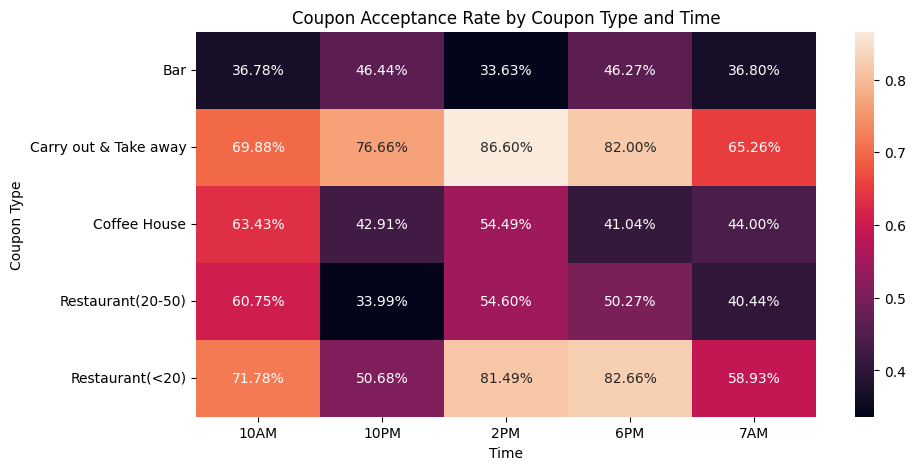

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(coupon_time,annot=True,fmt=".2%")
plt.title("Coupon Acceptance Rate by Coupon Type and Time")
plt.xlabel("Time")
plt.ylabel("Coupon Type")
plt.show()

### Interpretation

The heatmap shows how coupon acceptance varies across different coupon types and times of the day.
### Business Insights
- Bar: Acceptance is highest at 10 PM (46.44%) and lowest at 2 PM (33.63%).
- Carry out & Take away: Acceptance is highest at 2 PM (86.60%) and lowest at 7 AM (65.26%).
- Coffee House: Acceptance is highest at 10 AM (63.43%) and lowest at 6 PM (41.04%).
- Restaurant (20–50): Acceptance is highest at 10 AM (60.75%) and lowest at 10 PM (33.99%).
- **Restaurant (< 20): Acceptance is highest at 6 PM (82.66%) and lowest at 10 PM (50.68%)

In [ ]:
coupon_summary=df.groupby("coupon")["Y"].agg(Acceptance_Rate="mean",Total_Offers="count").reset_index()
coupon_summary["Acceptance_Rate"]=(coupon_summary["Acceptance_Rate"]*100).round(2)
coupon_summary

,coupon,Acceptance_Rate,Total_Offers
0,Bar,41.19,1906
1,Carry out & Take away,73.58,2233
2,Coffee House,49.57,3809
3,Restaurant(20-50),44.66,1413
4,Restaurant(<20),70.98,2646


### Coupon Performance Summary

A summary table was created to compare the number of coupon offers and the acceptance rate for each coupon category.

- Bar: Has an acceptance rate of 41.19% from 1,906 coupon offers.
- Carry out & Take away: Has a high acceptance rate of 73.58% from 2,233 offers.
- Coffee House: Has the highest number of offers (3,809), with an acceptance rate of 49.57%.
- Restaurant (20–50): Has the lowest acceptance rate of 44.66% among 1,413 offers.
- Restaurant (< 20): Has an acceptance rate of 70.98% from 2,646 coupon offers.

In [ ]:
plotly_profile=df.groupby(["age","gender"], as_index=False).agg(offers=("Y","size"),
    acceptance_rate_pct=("Y",lambda s:s.mean()*100))
fig=px.scatter(
    plotly_profile,x="age", y="acceptance_rate_pct",color="gender",
    size="offers",hover_data=["offers"],
    title="Interactive:Acceptance Rate by Age and Gender",
    labels={"age":"Age group","acceptance_rate_pct":"Acceptance rate (%)","gender":"Gender"}
)
fig.update_yaxes(range=[0, 100],ticksuffix="%")
fig.show()

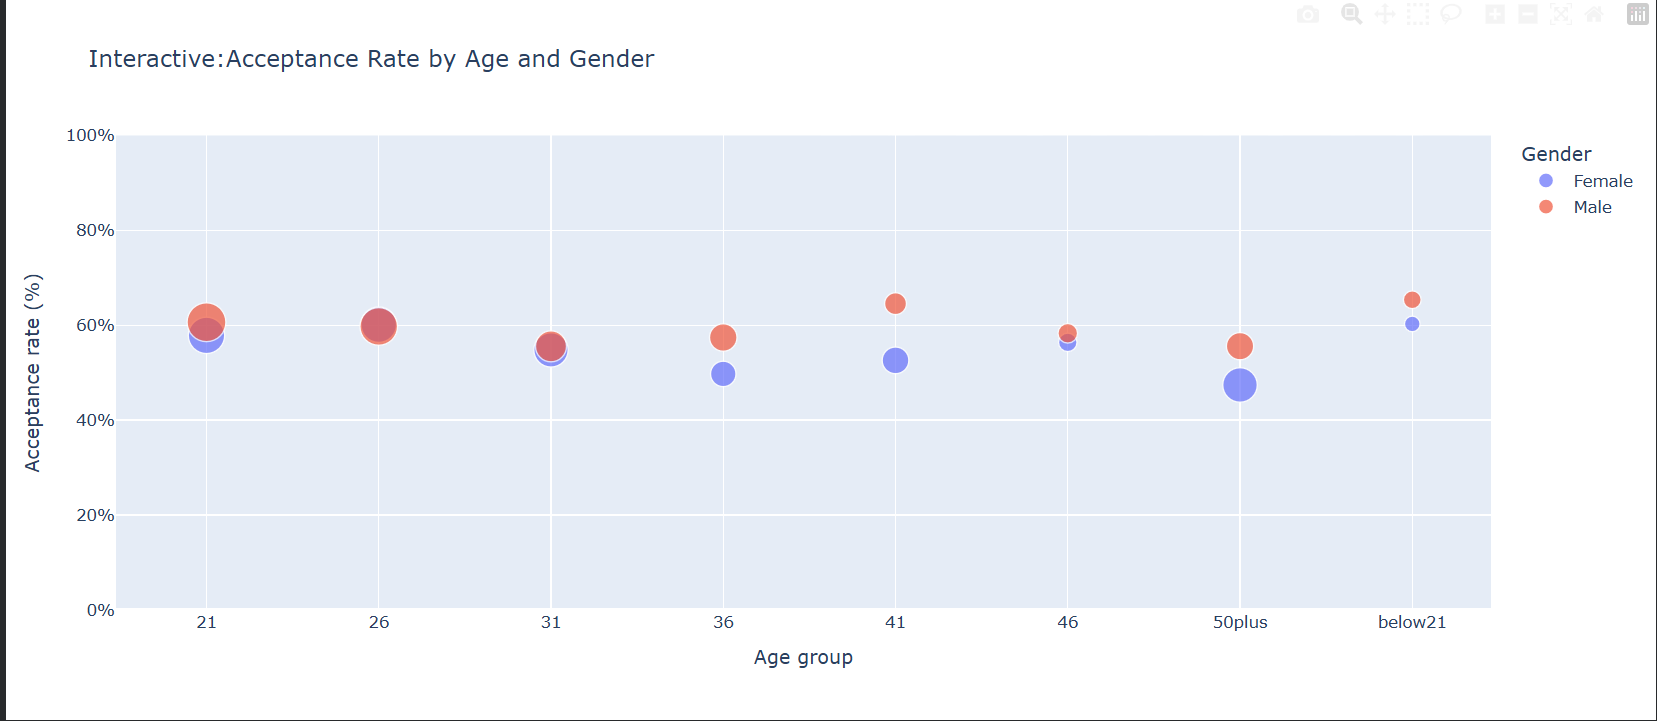

**Interpretation:**

The interactive bubble chart compares coupon acceptance rates across different age groups and genders. Each bubble represents an age-gender combination. The position of the bubble indicates the acceptance rate, while its size represents the total number of coupon offers.

**Business Insight:**

This analysis helps businesses identify age and gender segments associated with higher coupon acceptance rates. By considering both acceptance rates and the number of offers, businesses can make more informed decisions about customer targeting and promotional campaigns.

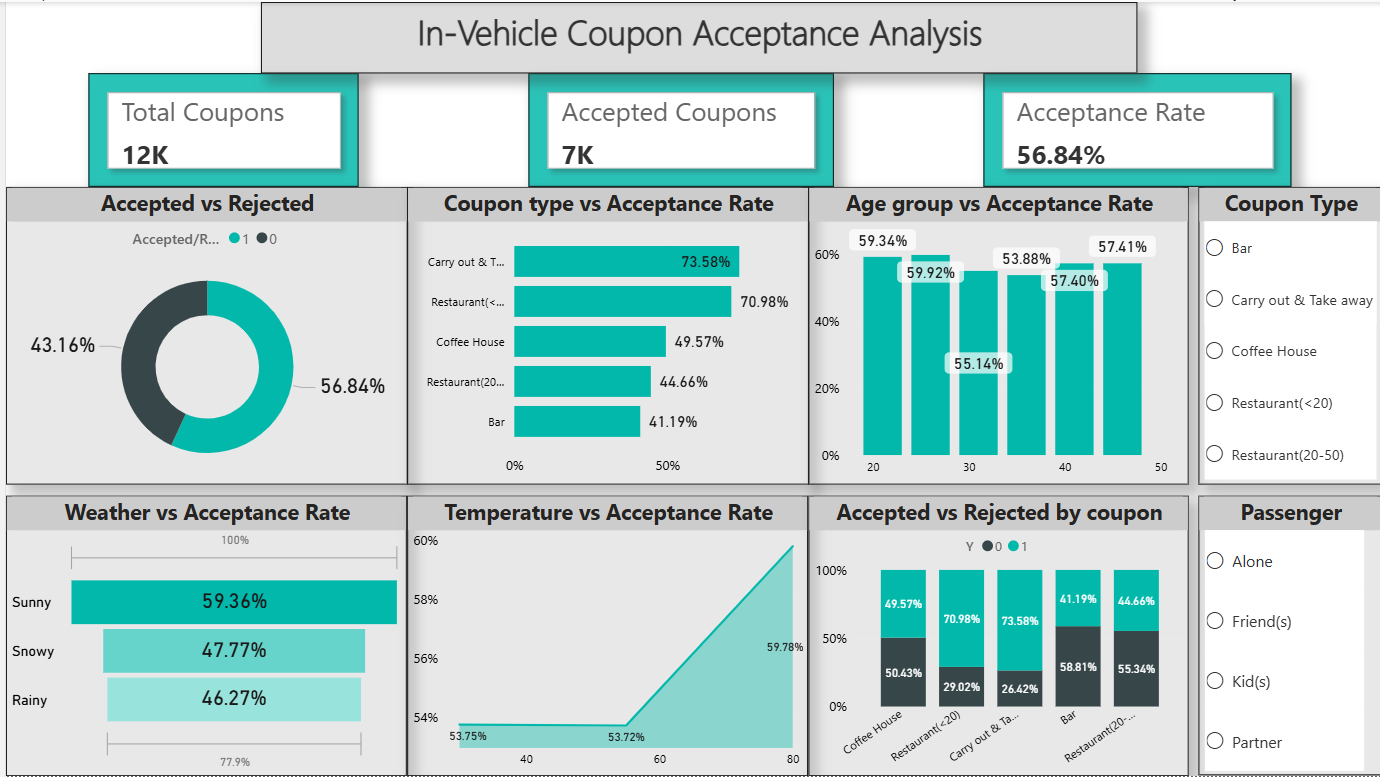

### Power BI Dashboard

An interactive Power BI dashboard was created to summarize the key findings of the In-Vehicle Coupon Acceptance Analysis project.

The dashboard includes KPI cards displaying the total coupons, accepted coupons, and overall acceptance rate.

Visualizations help compare accepted and rejected coupons and analyze acceptance rates across different coupon types and weather conditions.

Interactive slicers allow users to filter the dashboard and explore coupon acceptance patterns based on selected categories.

**Business Insight:**

The dashboard helps identify which coupon categories perform better and how acceptance patterns vary across different conditions.

These insights can help businesses plan more relevant and targeted coupon campaigns instead of distributing the same offers randomly.

**Outcome:**

The dashboard transforms the Python analysis into an easy-to-understand visual report, supporting data-driven marketing decisions.

### Final Overall Insights

1. Overall result: The cleaned dataset contains 12,007 offers. 6,825 (56.84%) were accepted and 5,182 (43.16%) were rejected.
2. Coupon type: Carry out & Take away had the highest acceptance rate (73.58%, 2,233 offers), followed by Restaurant(<20) (70.98%, 2,646 offers). Bar had the lowest rate (41.19%, 1,906 offers).
3. Travel context: No Urgent Place had 63.36% acceptance (5,953 offers). Sunny weather had 59.36% acceptance (9,545 offers). Acceptance was highest at 2 PM (66.07%, 1,913 offers) among the recorded time groups.
4. Expiration: One-day coupons had 62.65% acceptance (6,702 offers), compared with 49.50% for two-hour coupons (5,305 offers).
5. Passenger type: Offers to customers travelling with Friend(s) had 67.60% acceptance (3,142 offers).
6. Customer profile: The below21 age group had 63.15% acceptance (502 offers), while 50plus had 50.55% (1,725 offers). Male acceptance was 59.14% and female acceptance was 54.66%.
7. Multivariate patterns: Carry out & Take away acceptance was 86.60% at 2 PM and 76.28% in Sunny weather. Restaurant(<20) acceptance was 82.66% at 6 PM and 76.79% in Sunny weather.


# Business Recommendations

- Prioritize controlled tests for Carry out & Take away and Restaurant(<20) offers, which showed relatively high acceptance in this dataset.
- Investigate the lower acceptance rates for Bar and Restaurant(20–50) coupons; review discount value, location, timing and customer relevance.
- Test time-aware campaigns, especially around 2 PM, while comparing results by coupon type.
- Consider travel context and venue-visiting habits for personalization, but do not use demographic categories as the sole targeting rule.
- Report both acceptance rate and offer count. A high percentage from a small group may be unstable.
- Use A/B testing and measure redemption, incremental revenue, profit and customer experience before adopting campaign changes.

### Limitations
- The analysis uses one supplied dataset and may not represent all drivers, regions or campaigns.
- The car column was dropped because about 99.15% of its values were missing.
- Rows with any remaining missing values were dropped, leaving 12,007 rows. This can introduce selection bias; a future version could compare this approach with categorical imputation or an Unknown category.
- Some customer groups have smaller sample sizes, so their percentages are less stable.
- The dataset includes acceptance outcome, not profit or incremental sales.
- The analysis identifies associations, not causal relationships.
- The toCoupon_GEQ5min indicator has no useful variation for a group comparison in this dataset.

### Future Enhancements
1. **Customer Segmentation:** Group customers based on their visiting habits, travel conditions, and coupon preferences to understand different customer behaviors.

2. **Time-Based Campaign Analysis:** Analyze which coupon types perform better at different times of the day to support more relevant promotional campaigns.

3. **A/B Testing:** In the future, compare two different coupon strategies to identify which one achieves better acceptance rates.

4. **Business Performance Analysis:** Include actual coupon redemption, sales, and revenue data to understand whether accepted coupons lead to successful purchases.

# Conclusion
This project analyzed 12,007 cleaned coupon offers to understand patterns in customer coupon acceptance. The analysis covered coupon types, travel conditions, customer characteristics, visiting habits, expiration, travel-time indicators and direction. Multiple static chart types and interactive Plotly charts were used to communicate the findings.

The results suggest that coupon type, time, destination, weather and passenger context are associated with differences in acceptance. The findings can help form targeted marketing hypotheses, but controlled experiments and business outcome measures are needed before making campaign decisions.

In [ ]:
cleaned_output = "cleaned_in_vehicle_coupon_recommendation.csv"
df.to_csv(cleaned_output, index=False)
print("Saved:", cleaned_output)
print("Rows:", len(df), "| Columns:", len(df.columns))
from google.colab import files
files.download(cleaned_output)

Saved: cleaned_in_vehicle_coupon_recommendation.csv
Rows: 12007 | Columns: 25


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>